In [11]:
import pandas as pd
import numpy as np

df = pd.read_csv("student_dropout_risk_2026.csv")

print("Shape:", df.shape)
print("\nColumn Types:\n", df.dtypes)
print("\nTotal Missing Cells:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate person_id:", df["person_id"].duplicated().sum())

dropout_rate = df["dropout"].mean()
majority_acc = 1.0 - dropout_rate
print(f"\nDropout Rate: {dropout_rate:.5f} ({dropout_rate*100:.2f}%)")
print(f"Always 'No Dropout' Accuracy: {majority_acc:.5f} ({majority_acc*100:.2f}%)")

Shape: (100000, 34)

Column Types:
 person_id                         int64
age                               int64
gender                              str
nationality                         str
first_generation                  int64
disability_status                 int64
family_income_level                 str
scholarship_holder                int64
tuition_up_to_date                int64
part_time_job                     int64
weekly_work_hours                 int64
course_type                         str
study_mode                          str
semester                          int64
international_student             int64
admission_grade                 float64
previous_qualification_grade    float64
units_enrolled                    int64
units_passed                      int64
units_failed                      int64
gpa_semester_1                  float64
gpa_semester_2                  float64
attendance_rate                 float64
assignments_submitted_rate      float64
libr

In [12]:
range_rules = {
    "age": (15, 100),
    "first_generation": (0, 1),
    "disability_status": (0, 1),
    "scholarship_holder": (0, 1),
    "tuition_up_to_date": (0, 1),
    "part_time_job": (0, 1),
    "weekly_work_hours": (0, 80),
    "semester": (1, 16),
    "international_student": (0, 1),
    "admission_grade": (0, 200),
    "previous_qualification_grade": (0, 200),
    "units_enrolled": (0, 40),
    "units_passed": (0, 40),
    "units_failed": (0, 40),
    "gpa_semester_1": (0.0, 4.0),
    "gpa_semester_2": (0.0, 4.0),
    "attendance_rate": (0.0, 100.0),
    "assignments_submitted_rate": (0.0, 100.0),
    "library_visits_per_month": (0, 100),
    "lms_logins_per_week": (0.0, 168.0),
    "extracurricular_activities": (0, 1),
    "missed_deadlines": (0, 50),
    "stress_level": (1, 10),
    "mental_health_support": (0, 1),
    "satisfaction_score": (1, 10),
    "commute_time_mins": (0, 300),
    "sleep_hours": (0.0, 24.0),
}

out_of_range = {
    col: int(((df[col] < lo) | (df[col] > hi)).sum())
    for col, (lo, hi) in range_rules.items()
}
print("Out-of-range counts:", out_of_range)

units_mismatch = (df["units_passed"] + df["units_failed"] != df["units_enrolled"]).sum()
work_without_job = ((df["weekly_work_hours"] > 0) & (df["part_time_job"] != 1)).sum()
job_without_work = ((df["weekly_work_hours"] == 0) & (df["part_time_job"] == 1)).sum()

print("Units mismatch count:", units_mismatch)
print("Work hours > 0 without part_time_job == 1:", work_without_job)
print("Work hours == 0 with part_time_job == 1:", job_without_work)

print("\nYoungest ages:\n", df["age"].value_counts().sort_index().head(5))
print("\nLowest 10 admission grades:\n", df["admission_grade"].nsmallest(10))

Out-of-range counts: {'age': 0, 'first_generation': 0, 'disability_status': 0, 'scholarship_holder': 0, 'tuition_up_to_date': 0, 'part_time_job': 0, 'weekly_work_hours': 0, 'semester': 0, 'international_student': 0, 'admission_grade': 0, 'previous_qualification_grade': 0, 'units_enrolled': 0, 'units_passed': 0, 'units_failed': 0, 'gpa_semester_1': 0, 'gpa_semester_2': 0, 'attendance_rate': 0, 'assignments_submitted_rate': 0, 'library_visits_per_month': 0, 'lms_logins_per_week': 0, 'extracurricular_activities': 0, 'missed_deadlines': 0, 'stress_level': 0, 'mental_health_support': 0, 'satisfaction_score': 0, 'commute_time_mins': 0, 'sleep_hours': 0}
Units mismatch count: 0
Work hours > 0 without part_time_job == 1: 0
Work hours == 0 with part_time_job == 1: 0

Youngest ages:
 age
15    4406
16    3347
17    5005
18    6862
19    8878
Name: count, dtype: int64

Lowest 10 admission grades:
 86400     5.5
15648    19.6
46085    20.8
65046    21.1
7207     21.8
5934     23.1
22468    25.3
55

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\empty\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\empty\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


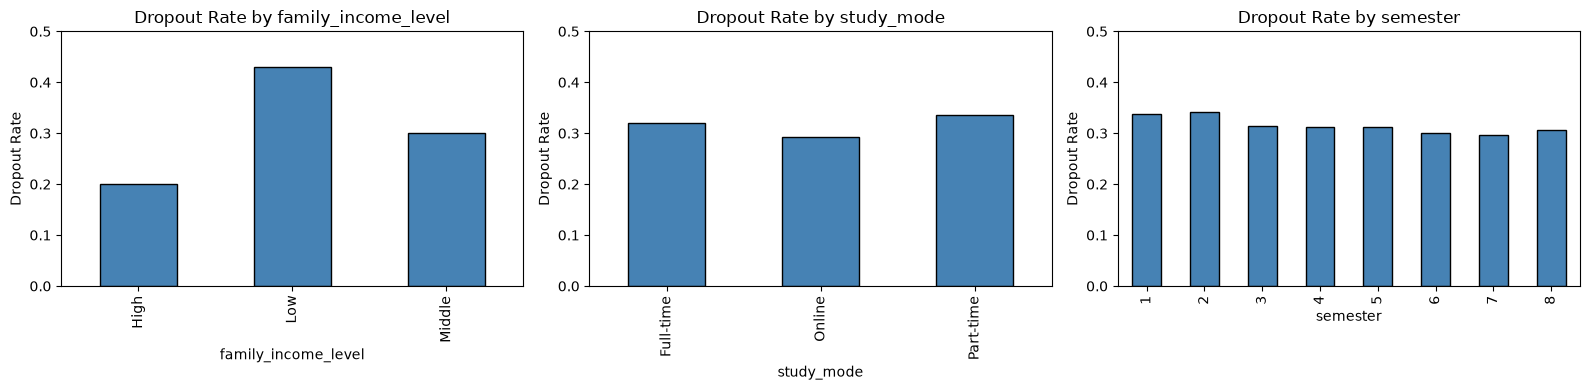

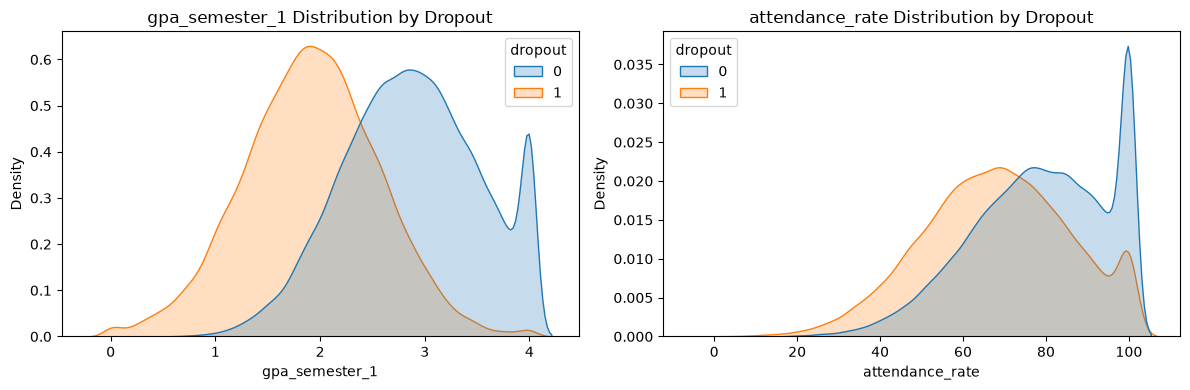

gpa_semester_1       | |r| = 0.5688 | r = -0.5688
gpa_semester_2       | |r| = 0.5214 | r = -0.5214
units_failed         | |r| = 0.4667 | r = +0.4667
attendance_rate      | |r| = 0.2846 | r = -0.2846
missed_deadlines     | |r| = 0.2819 | r = +0.2819


In [15]:
%pip install matplotlib
%pip install seaborn

import matplotlib.pyplot as plt
import seaborn as sns

# (a) Dropout rate by family_income_level, study_mode, and semester
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["family_income_level", "study_mode", "semester"]):
    rates = df.groupby(col)["dropout"].mean()
    rates.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
    ax.set_title(f"Dropout Rate by {col}")
    ax.set_ylabel("Dropout Rate")
    ax.set_ylim(0, 0.5)
plt.tight_layout()
plt.show()

# (b) Distributions of gpa_semester_1 and attendance_rate by dropout
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["gpa_semester_1", "attendance_rate"]):
    sns.kdeplot(data=df, x=col, hue="dropout", common_norm=False, fill=True, ax=ax)
    ax.set_title(f"{col} Distribution by Dropout")
plt.tight_layout()
plt.show()

# (c) Top 5 numeric columns by absolute correlation with dropout
num_cols = df.select_dtypes(include=[np.number]).columns.drop(["person_id", "dropout"])
corrs = df[num_cols].apply(lambda s: s.corr(df["dropout"]))
top5 = corrs.abs().sort_values(ascending=False).head(5)
for col in top5.index:
    print(f"{col:20s} | |r| = {top5[col]:.4f} | r = {corrs[col]:+.4f}")

In [16]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["dropout"])
y = df["dropout"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Full dropout share:  {y.mean():.5f} (n={len(y)})")
print(f"Train dropout share: {y_train.mean():.5f} (n={len(y_train)})")
print(f"Test dropout share:  {y_test.mean():.5f} (n={len(y_test)})")

Full dropout share:  0.32004 (n=100000)
Train dropout share: 0.32004 (n=80000)
Test dropout share:  0.32005 (n=20000)


In [19]:
from dropout_transformers import ColumnDropper, RangeCleaner, FeatureEngineer

sample = X_train.head(3).copy()
sample.loc[sample.index[0], "attendance_rate"] = 140.0  # deliberate corruption

s1 = ColumnDropper().fit_transform(sample)
print("person_id in columns after ColumnDropper:", "person_id" in s1.columns)

s2 = RangeCleaner().fit_transform(s1)
print("Corrupted attendance_rate after RangeCleaner:", s2["attendance_rate"].iloc[0])

s3 = FeatureEngineer(add_features=True).fit_transform(s2)
print("Engineered columns added:", [c for c in s3.columns if c not in s2.columns])

person_id in columns after ColumnDropper: False
Corrupted attendance_rate after RangeCleaner: nan
Engineered columns added: ['pass_rate', 'gpa_change', 'engagement_index', 'work_hours_per_unit', 'financial_risk_flag']


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from dropout_transformers import ColumnDropper, RangeCleaner, FeatureEngineer


def build_pipeline(model, add_features=True, drop=None):
    cols_to_drop = ["person_id"] + (drop if drop is not None else [])

    num_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    cat_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    preprocessor = ColumnTransformer([
        ("num", num_pipeline, make_column_selector(dtype_include=np.number)),
        ("cat", cat_pipeline, make_column_selector(dtype_include=["object", "category"])),
    ])

    return Pipeline([
        ("dropper", ColumnDropper(cols_to_drop=cols_to_drop)),
        ("cleaner", RangeCleaner()),
        ("fe", FeatureEngineer(add_features=add_features)),
        ("preprocessor", preprocessor),
        ("model", model),
    ])


# Fit preprocessor on training data only and transform both sets
prep_pipeline = build_pipeline(model="passthrough", add_features=True)
X_train_proc = prep_pipeline.fit_transform(X_train)
X_test_proc = prep_pipeline.transform(X_test)

print("X_train_proc shape:", X_train_proc.shape)
print("X_test_proc shape:", X_test_proc.shape)
print("NaNs in train / test:", np.isnan(X_train_proc).sum(), "/", np.isnan(X_test_proc).sum())
print("First 10 output columns:", list(prep_pipeline.named_steps["preprocessor"].get_feature_names_out()[:10]))
print("Test numeric column means (first 5):", X_test_proc[:, :5].mean(axis=0).round(4))

X_train_proc shape: (80000, 61)
X_test_proc shape: (20000, 61)
NaNs in train / test: 0 / 0
First 10 output columns: ['num__age', 'num__first_generation', 'num__disability_status', 'num__scholarship_holder', 'num__tuition_up_to_date', 'num__part_time_job', 'num__weekly_work_hours', 'num__semester', 'num__international_student', 'num__admission_grade']
Test numeric column means (first 5): [ 0.0001 -0.0025  0.0018 -0.0047 -0.0104]


In [21]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "Dummy (most_frequent)": DummyClassifier(strategy="most_frequent"),
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "DecisionTree (max_depth=6)": DecisionTreeClassifier(max_depth=6, random_state=42),
    "RandomForest (150 trees)": RandomForestClassifier(
        n_estimators=150, min_samples_leaf=5, random_state=42, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "roc_auc", "f1", "recall", "precision"]

rows = []
for name, clf in models.items():
    pipe = build_pipeline(clf, add_features=True)
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "Model": name,
        "Mean Accuracy": res["test_accuracy"].mean(),
        "Mean ROC-AUC": res["test_roc_auc"].mean(),
        "Mean F1": res["test_f1"].mean(),
        "Mean Recall": res["test_recall"].mean(),
        "Mean Precision": res["test_precision"].mean(),
        "Mean Fit Time (s)": res["fit_time"].mean(),
    })

results_df = pd.DataFrame(rows)
print(results_df.to_string(index=False, float_format="%.4f"))

                     Model  Mean Accuracy  Mean ROC-AUC  Mean F1  Mean Recall  Mean Precision  Mean Fit Time (s)
     Dummy (most_frequent)         0.6800        0.5000   0.0000       0.0000          0.0000             1.2829
        LogisticRegression         0.8403        0.9039   0.7363       0.6968          0.7806             1.7085
DecisionTree (max_depth=6)         0.8096        0.8693   0.6830       0.6411          0.7310             2.6508
  RandomForest (150 trees)         0.8293        0.8939   0.7113       0.6568          0.7756            16.7728
      HistGradientBoosting         0.8376        0.9003   0.7326       0.6950          0.7744             8.5170


In [22]:
balanced_models = {
    "LogisticRegression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest (balanced)": RandomForestClassifier(
        n_estimators=150, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

bal_rows = []
for name, clf in balanced_models.items():
    pipe = build_pipeline(clf, add_features=True)
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    bal_rows.append({
        "Model": name,
        "Mean Accuracy": res["test_accuracy"].mean(),
        "Mean Recall": res["test_recall"].mean(),
        "Mean Precision": res["test_precision"].mean(),
    })

print(pd.DataFrame(bal_rows).to_string(index=False, float_format="%.4f"))

                        Model  Mean Accuracy  Mean Recall  Mean Precision
LogisticRegression (balanced)         0.8189       0.8248          0.6786
      RandomForest (balanced)         0.8184       0.7843          0.6904


In [23]:
ablation_models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
}

ablation_rows = []
for name, clf in ablation_models.items():
    for flag in [False, True]:
        pipe = build_pipeline(clf, add_features=flag)
        scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)["test_score"]
        ablation_rows.append({
            "Model": name,
            "add_features": flag,
            "Mean ROC-AUC": scores.mean(),
            "Std ROC-AUC": scores.std(),
        })

print(pd.DataFrame(ablation_rows).to_string(index=False, float_format="%.5f"))

               Model  add_features  Mean ROC-AUC  Std ROC-AUC
  LogisticRegression         False       0.90390      0.00172
  LogisticRegression          True       0.90391      0.00172
HistGradientBoosting         False       0.90011      0.00141
HistGradientBoosting          True       0.90029      0.00167


Test ROC-AUC: 0.9004

Classification Report:
               precision    recall  f1-score   support

           0     0.8621    0.9060    0.8835     13599
           1     0.7761    0.6921    0.7317      6401

    accuracy                         0.8376     20000
   macro avg     0.8191    0.7991    0.8076     20000
weighted avg     0.8346    0.8376    0.8349     20000

Confusion Matrix:
 [[12321  1278]
 [ 1971  4430]]
Missed dropouts (False Negatives): 1971
Students flagged by mistake (False Positives): 1278


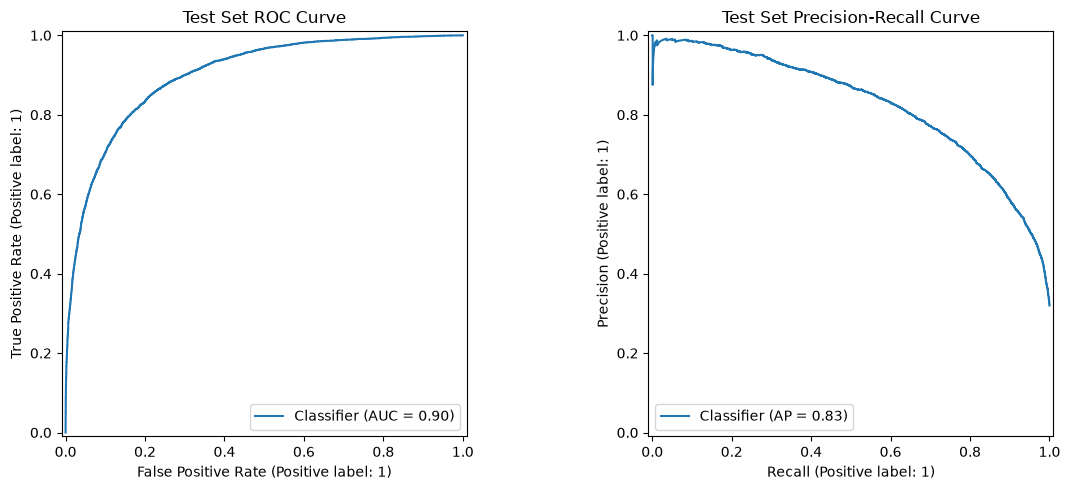

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    roc_auc_score,
)

best_pipe = build_pipeline(HistGradientBoostingClassifier(random_state=42), add_features=True)
best_pipe.fit(X_train, y_train)

y_test_pred = best_pipe.predict(X_test)
y_test_prob = best_pipe.predict_proba(X_test)[:, 1]

print(f"Test ROC-AUC: {roc_auc_score(y_test, y_test_prob):.4f}\n")
print("Classification Report:\n", classification_report(y_test, y_test_pred, digits=4))

cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion Matrix:\n", cm)
print(f"Missed dropouts (False Negatives): {fn}")
print(f"Students flagged by mistake (False Positives): {fp}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_test_prob, ax=axes[0])
axes[0].set_title("Test Set ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, y_test_prob, ax=axes[1])
axes[1].set_title("Test Set Precision-Recall Curve")
plt.tight_layout()
plt.show()

In [25]:
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, precision_score, recall_score

oof_probs = cross_val_predict(
    best_pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_probs)
# recalls has length len(thresholds) + 1; align indices with thresholds
valid_indices = np.where(recalls[:-1] >= 0.80)[0]
chosen_threshold = float(thresholds[valid_indices[-1]])

print(f"Highest OOF threshold with recall >= 0.80: {chosen_threshold:.4f}\n")

for label, thresh in [("Default (0.50)", 0.50), (f"Chosen ({chosen_threshold:.4f})", chosen_threshold)]:
    preds = (y_test_prob >= thresh).astype(int)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    share_flagged = preds.mean()
    print(f"{label:20s} | Test Precision: {prec:.4f} | Test Recall: {rec:.4f} | Flagged Share: {share_flagged:.4f}")

Highest OOF threshold with recall >= 0.80: 0.3463

Default (0.50)       | Test Precision: 0.7761 | Test Recall: 0.6921 | Flagged Share: 0.2854
Chosen (0.3463)      | Test Precision: 0.6998 | Test Recall: 0.7980 | Flagged Share: 0.3649


In [26]:
import time
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [15, 31],
    "model__min_samples_leaf": [20, 100],
}

grid_search = GridSearchCV(
    estimator=build_pipeline(HistGradientBoostingClassifier(random_state=42), add_features=True),
    param_grid=param_grid,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1,
)

t0 = time.perf_counter()
grid_search.fit(X_train, y_train)
wall_time = time.perf_counter() - t0

n_candidates = len(grid_search.cv_results_["params"])
n_fits = n_candidates * 3

print(f"Number of candidates: {n_candidates}")
print(f"Total pipeline fits:  {n_fits}")
print(f"Wall time:            {wall_time:.2f}s")
print(f"Best parameters:      {grid_search.best_params_}")
print(f"Best 3-fold CV AUC:   {grid_search.best_score_:.5f}")

Number of candidates: 8
Total pipeline fits:  24
Wall time:            80.57s
Best parameters:      {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 100}
Best 3-fold CV AUC:   0.90020


Tuned Model Test ROC-AUC: 0.90092

Top 10 Raw Input Columns by Permutation Importance:
                    feature  importance_mean  importance_std
            gpa_semester_1         0.077839        0.001398
            gpa_semester_2         0.015212        0.000593
           attendance_rate         0.011694        0.000614
        tuition_up_to_date         0.010468        0.000418
          missed_deadlines         0.005543        0.000387
       lms_logins_per_week         0.005393        0.000386
       family_income_level         0.005354        0.000415
assignments_submitted_rate         0.004789        0.000321
              stress_level         0.004208        0.000321
         weekly_work_hours         0.003836        0.000395


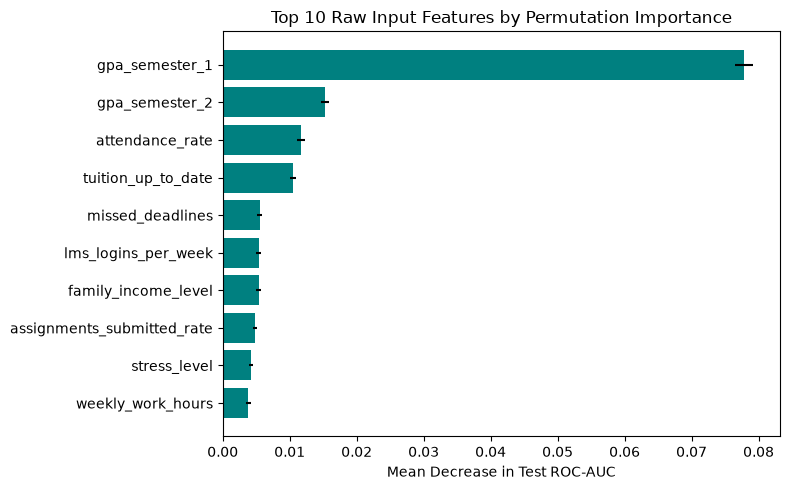

In [27]:
from sklearn.inspection import permutation_importance

tuned_pipe = grid_search.best_estimator_
tuned_test_auc = roc_auc_score(y_test, tuned_pipe.predict_proba(X_test)[:, 1])
print(f"Tuned Model Test ROC-AUC: {tuned_test_auc:.5f}")

perm_result = permutation_importance(
    tuned_pipe,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
}).sort_values("importance_mean", ascending=False)

top10 = perm_df.head(10)
print("\nTop 10 Raw Input Columns by Permutation Importance:\n", top10.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(top10["feature"][::-1], top10["importance_mean"][::-1], xerr=top10["importance_std"][::-1], color="teal")
plt.xlabel("Mean Decrease in Test ROC-AUC")
plt.title("Top 10 Raw Input Features by Permutation Importance")
plt.tight_layout()
plt.show()

In [28]:
import dask.dataframe as dd

ddf = dd.read_csv("student_dropout_risk_2026.csv", blocksize="2MB")
print("Number of partitions:", ddf.npartitions)

dask_course = ddf.groupby("course_type")["dropout"].mean().compute()
pandas_course = df.groupby("course_type")["dropout"].mean()

dask_income = ddf.groupby("family_income_level")["dropout"].mean().compute()
pandas_income = df.groupby("family_income_level")["dropout"].mean()

print("\nDropout by course_type (max abs diff):", (dask_course - pandas_course).abs().max())
print(dask_course)
print("\nDropout by family_income_level (max abs diff):", (dask_income - pandas_income).abs().max())
print(dask_income)

Number of partitions: 6

Dropout by course_type (max abs diff): 0.0
course_type
Arts & Humanities        0.321016
Business                 0.318458
Health Sciences          0.321130
Law & Social Sciences    0.316930
STEM                     0.321456
Name: dropout, dtype: float64

Dropout by family_income_level (max abs diff): 0.0
family_income_level
High      0.199896
Low       0.429199
Middle    0.300177
Name: dropout, dtype: float64


In [29]:
import joblib
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=2, threads_per_worker=2, processes=False)
client = Client(cluster)
print("Dask Dashboard:", client.dashboard_link)

def benchmark_grid_search(n_jobs_val, use_dask_backend=False):
    gs = GridSearchCV(
        estimator=build_pipeline(HistGradientBoostingClassifier(random_state=42), add_features=True),
        param_grid=param_grid,
        cv=3,
        scoring="roc_auc",
        n_jobs=n_jobs_val,
    )
    t0 = time.perf_counter()
    if use_dask_backend:
        with joblib.parallel_config(backend="dask"):
            gs.fit(X_train, y_train)
    else:
        gs.fit(X_train, y_train)
    elapsed = time.perf_counter() - t0
    return elapsed, gs.best_params_, gs.best_score_

t_serial, p_serial, s_serial = benchmark_grid_search(n_jobs_val=1, use_dask_backend=False)
t_loky, p_loky, s_loky = benchmark_grid_search(n_jobs_val=-1, use_dask_backend=False)
t_dask, p_dask, s_dask = benchmark_grid_search(n_jobs_val=-1, use_dask_backend=True)

timing_table = pd.DataFrame([
    {"Mode": "(a) Serial (n_jobs=1)", "Wall Time (s)": t_serial, "Best CV AUC": s_serial, "Best Params": str(p_serial)},
    {"Mode": "(b) Local Parallel (n_jobs=-1)", "Wall Time (s)": t_loky, "Best CV AUC": s_loky, "Best Params": str(p_loky)},
    {"Mode": "(c) Dask Backend (2x2 threads)", "Wall Time (s)": t_dask, "Best CV AUC": s_dask, "Best Params": str(p_dask)},
])
print(timing_table.to_string(index=False))

Dask Dashboard: http://10.5.0.2:8787/status
                          Mode  Wall Time (s)  Best CV AUC                                                                                Best Params
         (a) Serial (n_jobs=1)    5910.821478     0.900197 {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 100}
(b) Local Parallel (n_jobs=-1)     119.571321     0.900197 {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 100}
(c) Dask Backend (2x2 threads)     927.397119     0.900197 {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 100}


In [32]:
import dask
import dask.dataframe as dd
from dask_ml.wrappers import ParallelPostFit

# 1. Disable PyArrow string conversion BEFORE creating the Dask DataFrame
dask.config.set({"dataframe.convert-string": False})

# Simulate 500,000 rows (25x test set) split into 20 partitions
large_df = pd.concat([X_test] * 25, ignore_index=True)
large_ddf = dd.from_pandas(large_df, npartitions=20)

# Plain pandas inference
t0 = time.perf_counter()
pandas_probs = tuned_pipe.predict_proba(large_df)[:, 1]
t_pandas = time.perf_counter() - t0
pandas_rps = len(large_df) / t_pandas

# Dask ParallelPostFit inference
parallel_model = ParallelPostFit(estimator=tuned_pipe, scoring="roc_auc")
t0 = time.perf_counter()
dask_probs = parallel_model.predict_proba(large_ddf)[:, 1].compute()
t_dask = time.perf_counter() - t0
dask_rps = len(large_df) / t_dask

print(f"Plain pandas: {pandas_rps:,.0f} rows/sec ({t_pandas:.2f}s)")
print(f"Dask cluster: {dask_rps:,.0f} rows/sec ({t_dask:.2f}s)")

first_block_diff = np.max(np.abs(dask_probs[:len(X_test)] - pandas_probs[:len(X_test)]))
print(f"Max abs diff on first block: {first_block_diff:.15f}")

C:\Users\empty\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\distributed\client.py:3429: UserWarning: Sending large graph of size 142.51 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Plain pandas: 72,432 rows/sec (6.90s)
Dask cluster: 44,754 rows/sec (11.17s)
Max abs diff on first block: 0.000000000000000


In [33]:
import dask.array as da
from dask_ml.wrappers import Incremental
from sklearn.linear_model import SGDClassifier

# Fit preprocessor on training data only and transform train & test matrices
preprocessor_only = build_pipeline(model="passthrough", add_features=True)[:-1]
X_train_mat = preprocessor_only.fit_transform(X_train)
X_test_mat = preprocessor_only.transform(X_test)

# Split into Dask array chunks of 5,000 rows
X_train_da = da.from_array(X_train_mat, chunks=(5000, X_train_mat.shape[1]))
y_train_da = da.from_array(y_train.to_numpy(), chunks=(5000,))

sgd = SGDClassifier(loss="log_loss", random_state=42)
inc_model = Incremental(sgd, scoring="roc_auc")

for epoch in range(5):
    inc_model.partial_fit(X_train_da, y_train_da, classes=np.array([0, 1]))

sgd_probs = inc_model.predict_proba(X_test_mat)[:, 1]
sgd_auc = roc_auc_score(y_test, sgd_probs)
print(f"Incremental SGD (5 passes) Test ROC-AUC: {sgd_auc:.5f}")

C:\Users\empty\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\distributed\client.py:3429: UserWarning: Sending large graph of size 37.84 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
C:\Users\empty\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\distributed\client.py:3429: UserWarning: Sending large graph of size 37.85 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
C:\Users\empty\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\distributed\client.py:3429: UserWarning: Sending la

Incremental SGD (5 passes) Test ROC-AUC: 0.89351


In [34]:
from sklearn.model_selection import KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Remove 'dropout' (future outcome leakage) and target 'gpa_semester_2'
X_reg = df.drop(columns=["dropout", "gpa_semester_2"])
y_reg = df["gpa_semester_2"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

reg_models = {
    "DummyRegressor (mean)": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression(),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=10, random_state=42, n_jobs=-1
    ),
    "HistGradientBoostingRegressor": HistGradientBoostingRegressor(random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
reg_rows = []

for name, reg in reg_models.items():
    pipe = build_pipeline(reg, add_features=True, drop=["gpa_semester_2"])
    cv_mae = -cross_validate(
        pipe, Xr_train, yr_train, cv=kf, scoring="neg_mean_absolute_error", n_jobs=-1
    )["test_score"].mean()

    pipe.fit(Xr_train, yr_train)
    preds = pipe.predict(Xr_test)
    reg_rows.append({
        "Model": name,
        "CV MAE": cv_mae,
        "Test MAE": mean_absolute_error(yr_test, preds),
        "Test RMSE": root_mean_squared_error(yr_test, preds),
        "Test R2": r2_score(yr_test, preds),
    })

reg_results_df = pd.DataFrame(reg_rows)
print(reg_results_df.to_string(index=False, float_format="%.4f"))

                        Model  CV MAE  Test MAE  Test RMSE  Test R2
        DummyRegressor (mean)  0.5789    0.5801     0.7180  -0.0000
             LinearRegression  0.3174    0.3182     0.3979   0.6928
            Ridge (alpha=1.0)  0.3174    0.3182     0.3979   0.6928
        RandomForestRegressor  0.3200    0.3209     0.4011   0.6879
HistGradientBoostingRegressor  0.3181    0.3184     0.3980   0.6927


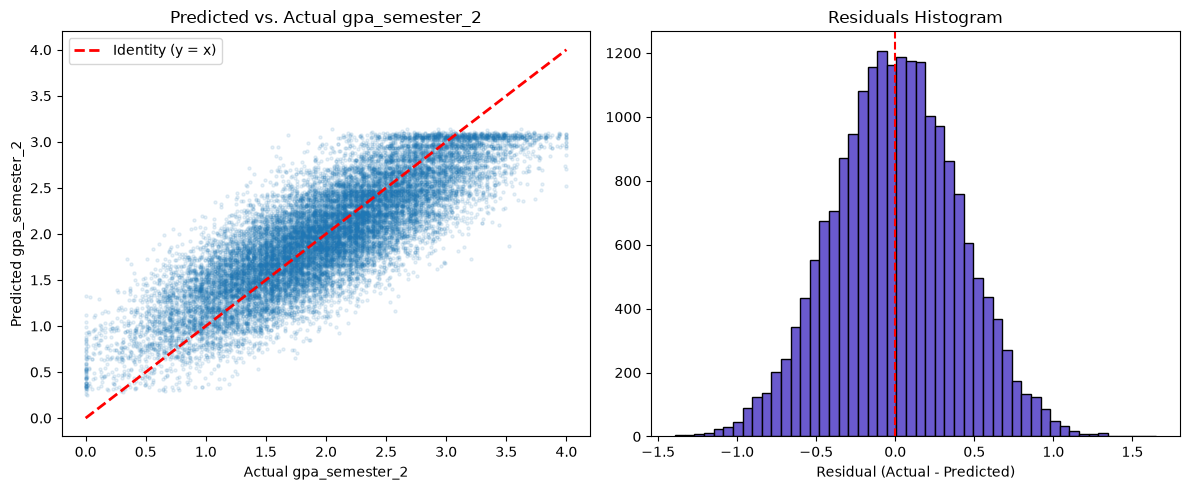

Low GPA (<1.0):  Actual mean=0.678 | Pred mean=1.073 | Bias=+0.395
High GPA (>3.5): Actual mean=3.685 | Pred mean=2.951 | Bias=-0.734


In [35]:
best_reg_pipe = build_pipeline(
    HistGradientBoostingRegressor(random_state=42), add_features=True, drop=["gpa_semester_2"]
)
best_reg_pipe.fit(Xr_train, yr_train)
yr_pred = best_reg_pipe.predict(Xr_test)
residuals = yr_test - yr_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(yr_test, yr_pred, alpha=0.1, s=5)
axes[0].plot([0, 4], [0, 4], "r--", lw=2, label="Identity (y = x)")
axes[0].set_xlabel("Actual gpa_semester_2")
axes[0].set_ylabel("Predicted gpa_semester_2")
axes[0].set_title("Predicted vs. Actual gpa_semester_2")
axes[0].legend()

axes[1].hist(residuals, bins=50, color="slateblue", edgecolor="black")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual (Actual - Predicted)")
axes[1].set_title("Residuals Histogram")
plt.tight_layout()
plt.show()

low_mask = yr_test < 1.0
high_mask = yr_test > 3.5
print(f"Low GPA (<1.0):  Actual mean={yr_test[low_mask].mean():.3f} | Pred mean={yr_pred[low_mask].mean():.3f} | Bias={ (yr_pred[low_mask] - yr_test[low_mask]).mean():+.3f}")
print(f"High GPA (>3.5): Actual mean={yr_test[high_mask].mean():.3f} | Pred mean={yr_pred[high_mask].mean():.3f} | Bias={ (yr_pred[high_mask] - yr_test[high_mask]).mean():+.3f}")

In [36]:
best_hgb_params = {k.replace("model__", ""): v for k, v in grid_search.best_params_.items()}

early_warning_pipe = build_pipeline(
    HistGradientBoostingClassifier(**best_hgb_params, random_state=42),
    add_features=True,
    drop=["gpa_semester_2"],
)
early_warning_pipe.fit(X_train, y_train)
ew_test_auc = roc_auc_score(y_test, early_warning_pipe.predict_proba(X_test)[:, 1])

print(f"Full Model Test ROC-AUC:          {tuned_test_auc:.5f}")
print(f"Early-Warning Model Test ROC-AUC: {ew_test_auc:.5f}")

Full Model Test ROC-AUC:          0.90092
Early-Warning Model Test ROC-AUC: 0.89763


In [37]:
import os
import sys
import json
import datetime
import sklearn
import joblib

model_file = "dropout_tuned_pipeline.joblib"
meta_file = "dropout_model_metadata.json"

joblib.dump(tuned_pipe, model_file)

metadata = {
    "creation_time_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "library_versions": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__,
    },
    "raw_input_columns": list(X_train.columns),
    "chosen_threshold": chosen_threshold,
    "best_hyperparameters": grid_search.best_params_,
    "test_metrics": {
        "roc_auc": float(tuned_test_auc),
        "precision_at_chosen_threshold": float(precision_score(y_test, (y_test_prob >= chosen_threshold).astype(int))),
        "recall_at_chosen_threshold": float(recall_score(y_test, (y_test_prob >= chosen_threshold).astype(int))),
    },
}

with open(meta_file, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print(f"{model_file} size: {os.path.getsize(model_file):,} bytes")
print(f"{meta_file} size:  {os.path.getsize(meta_file):,} bytes")

dropout_tuned_pipeline.joblib size: 220,762 bytes
dropout_model_metadata.json size:  1,415 bytes


In [38]:
import subprocess

# Save 500 test rows and notebook reference probabilities
X_test.head(500).to_csv("sample_500.csv", index=False)
notebook_preds_500 = tuned_pipe.predict_proba(X_test.head(500))[:, 1]
np.save("notebook_preds_500.npy", notebook_preds_500)

script_code = """
import joblib
import numpy as np
import pandas as pd

loaded_pipe = joblib.load("dropout_tuned_pipeline.joblib")
X_500 = pd.read_csv("sample_500.csv")
reloaded_preds = loaded_pipe.predict_proba(X_500)[:, 1]
notebook_preds = np.load("notebook_preds_500.npy")

max_abs_diff = float(np.max(np.abs(reloaded_preds - notebook_preds)))
print(f"Max absolute difference in fresh process: {max_abs_diff:.15f}")
assert max_abs_diff < 1e-12
"""

with open("reload_check.py", "w", encoding="utf-8") as f:
    f.write(script_code)

result = subprocess.run([sys.executable, "reload_check.py"], capture_output=True, text=True, check=True)
print(result.stdout.strip())

Max absolute difference in fresh process: 0.000000000000000


In [39]:
def test_probability_axioms():
    probs = tuned_pipe.predict_proba(X_test.head(100))
    assert probs.shape == (100, 2), f"Expected shape (100, 2), got {probs.shape}"
    assert np.all((probs >= 0.0) & (probs <= 1.0)), "Probabilities out of [0, 1] range"
    assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-6), "Probabilities do not sum to 1"


def test_resilience_to_dirty_inputs():
    corrupted = X_test.head(5).copy()
    corrupted.loc[corrupted.index[0], "gpa_semester_1"] = np.nan        # missing value
    corrupted.loc[corrupted.index[1], "nationality"] = "Unknown_Planet"  # unseen category
    corrupted.loc[corrupted.index[2], "attendance_rate"] = 250.0         # impossible value
    probs = tuned_pipe.predict_proba(corrupted)
    assert probs.shape == (5, 2), "Unexpected output shape on corrupted rows"
    assert not np.isnan(probs).any(), "NaNs appeared in output probabilities"


def test_reloaded_pipeline_matches_original():
    reloaded_pipe = joblib.load("dropout_tuned_pipeline.joblib")
    p_orig = tuned_pipe.predict_proba(X_test.head(200))[:, 1]
    p_load = reloaded_pipe.predict_proba(X_test.head(200))[:, 1]
    assert np.allclose(p_orig, p_load, atol=1e-12), "Reloaded pipeline predictions diverged"


def test_model_beats_dummy_floor():
    dummy_pipe = build_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
    dummy_auc = roc_auc_score(y_test, dummy_pipe.predict_proba(X_test)[:, 1])
    model_auc = roc_auc_score(y_test, tuned_pipe.predict_proba(X_test)[:, 1])
    assert model_auc > dummy_auc + 0.35, f"Model AUC ({model_auc:.4f}) failed quality floor over dummy ({dummy_auc:.4f})"


test_suite = [
    test_probability_axioms,
    test_resilience_to_dirty_inputs,
    test_reloaded_pipeline_matches_original,
    test_model_beats_dummy_floor,
]

for test_fn in test_suite:
    try:
        test_fn()
        print(f"PASS - {test_fn.__name__}")
    except AssertionError as e:
        print(f"FAIL - {test_fn.__name__}: {e}")

PASS - test_probability_axioms
PASS - test_resilience_to_dirty_inputs
PASS - test_reloaded_pipeline_matches_original
PASS - test_model_beats_dummy_floor
